In [1]:
%pip install pandas numpy matplotlib seaborn plotly

Note: you may need to restart the kernel to use updated packages.


COVID-19 Dataset
  Country Month  Confirmed  Recovered  Deaths  Vaccinated  Active
0   India   Jan      10000       8000     100        5000    1900
1   India   Feb      15000      12000     150       10000    2850
2   India   Mar      25000      20000     250       18000    4750
3   India   Apr      40000      33000     400       30000    6600
4     USA   Jan      20000      15000     200       10000    4800

Country-wise Statistics
         Confirmed  Recovered  Deaths  Vaccinated  Active
Country                                                  
Brazil       93000      73000     930       54000   19070
India        90000      73000     900       63000   16100
USA         155000     121000    1550      103000   32450


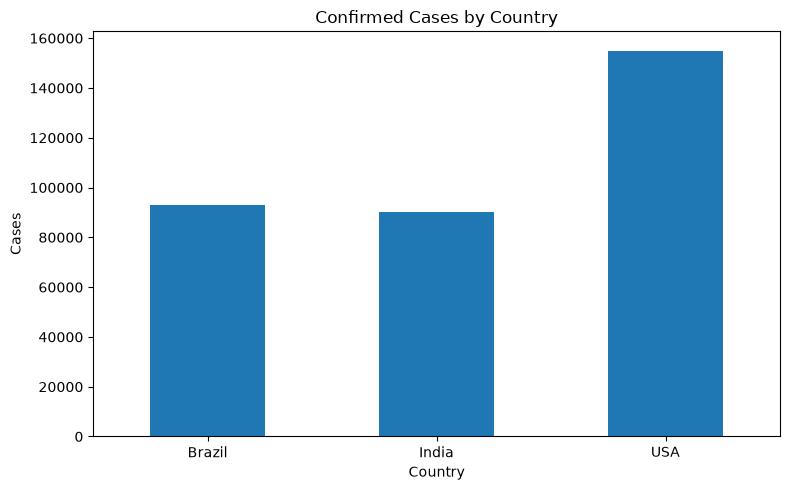

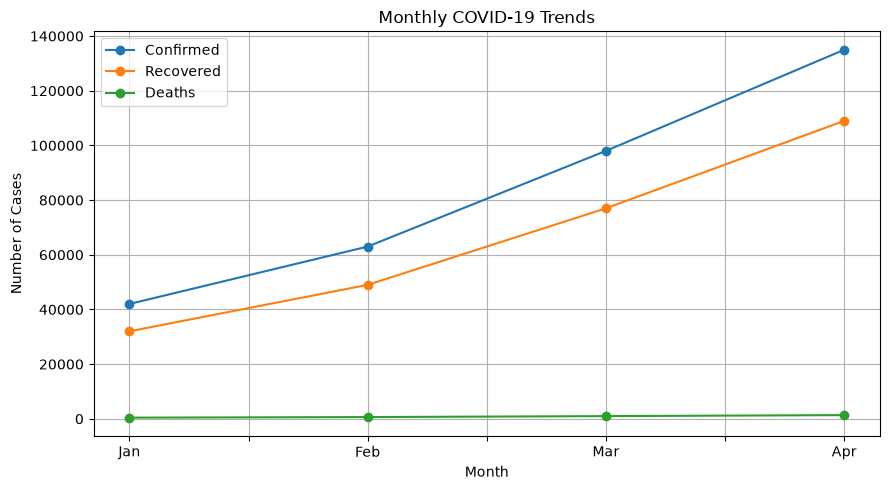

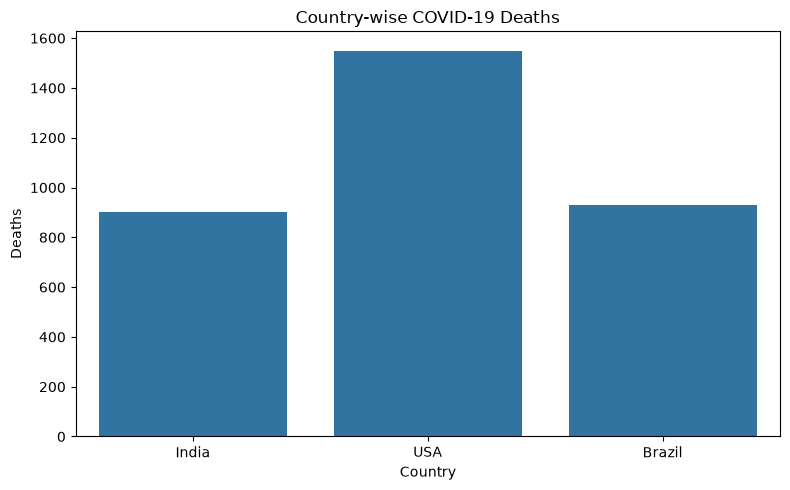

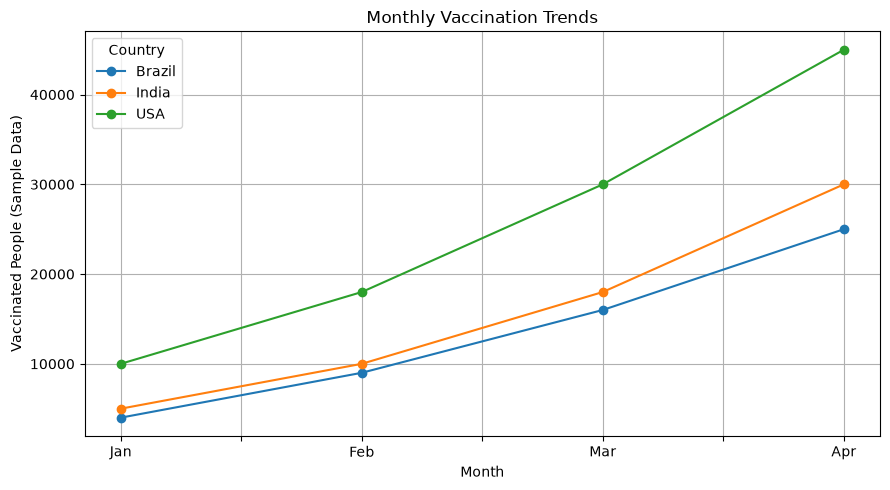

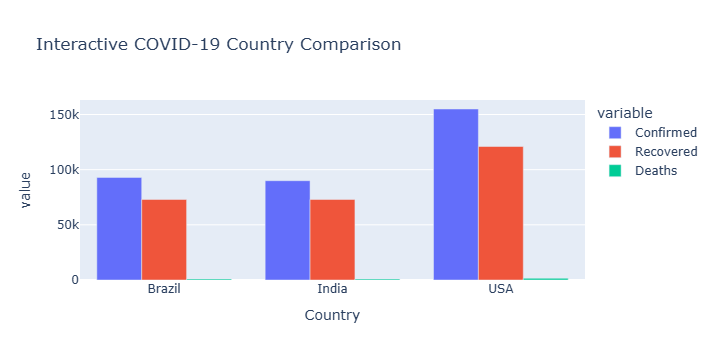

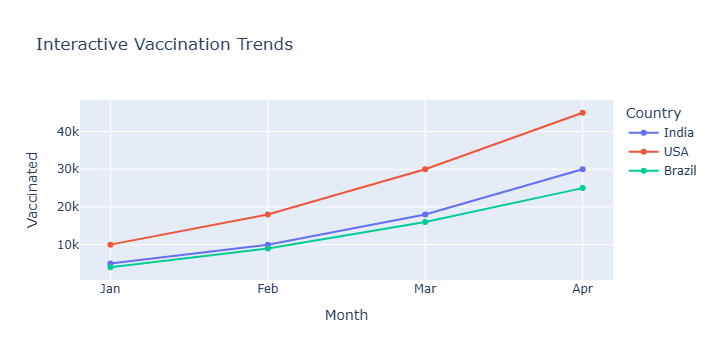


COVID-19 Analysis Dashboard Completed!


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Create sample COVID-19 dataset
data = {
    "Country": [
        "India", "India", "India", "India",
        "USA", "USA", "USA", "USA",
        "Brazil", "Brazil", "Brazil", "Brazil"
    ],
    "Month": [
        "Jan", "Feb", "Mar", "Apr",
        "Jan", "Feb", "Mar", "Apr",
        "Jan", "Feb", "Mar", "Apr"
    ],
    "Confirmed": [
        10000, 15000, 25000, 40000,
        20000, 30000, 45000, 60000,
        12000, 18000, 28000, 35000
    ],
    "Recovered": [
        8000, 12000, 20000, 33000,
        15000, 23000, 35000, 48000,
        9000, 14000, 22000, 28000
    ],
    "Deaths": [
        100, 150, 250, 400,
        200, 300, 450, 600,
        120, 180, 280, 350
    ],
    "Vaccinated": [
        5000, 10000, 18000, 30000,
        10000, 18000, 30000, 45000,
        4000, 9000, 16000, 25000
    ]
}

df = pd.DataFrame(data)

# Calculate active cases
df["Active"] = df["Confirmed"] - df["Recovered"] - df["Deaths"]

# Display dataset
print("COVID-19 Dataset")
print(df.head())

# Country-wise statistics
country_data = df.groupby("Country")[
    ["Confirmed", "Recovered", "Deaths", "Vaccinated", "Active"]
].sum()

print("\nCountry-wise Statistics")
print(country_data)

# 1. Confirmed cases by country
country_data["Confirmed"].plot(
    kind="bar", figsize=(8, 5), title="Confirmed Cases by Country"
)
plt.ylabel("Cases")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 2. Monthly confirmed cases
monthly_data = df.groupby("Month")[
    ["Confirmed", "Recovered", "Deaths"]
].sum()

month_order = ["Jan", "Feb", "Mar", "Apr"]
monthly_data = monthly_data.reindex(month_order)

monthly_data.plot(
    kind="line", marker="o", figsize=(9, 5),
    title="Monthly COVID-19 Trends"
)
plt.ylabel("Number of Cases")
plt.grid(True)
plt.tight_layout()
plt.show()

# 3. Deaths by country
plt.figure(figsize=(8, 5))
sns.barplot(
    data=df, x="Country", y="Deaths",
    estimator=sum, errorbar=None
)
plt.title("Country-wise COVID-19 Deaths")
plt.tight_layout()
plt.show()

# 4. Vaccination trends
df.pivot(
    index="Month", columns="Country", values="Vaccinated"
).reindex(month_order).plot(
    marker="o", figsize=(9, 5),
    title="Monthly Vaccination Trends"
)
plt.ylabel("Vaccinated People (Sample Data)")
plt.grid(True)
plt.tight_layout()
plt.show()

# 5. Interactive country-wise dashboard
fig = px.bar(
    country_data.reset_index(),
    x="Country",
    y=["Confirmed", "Recovered", "Deaths"],
    barmode="group",
    title="Interactive COVID-19 Country Comparison"
)
fig.show()

# 6. Interactive vaccination chart
fig = px.line(
    df,
    x="Month",
    y="Vaccinated",
    color="Country",
    markers=True,
    category_orders={"Month": month_order},
    title="Interactive Vaccination Trends"
)
fig.show()

print("\nCOVID-19 Analysis Dashboard Completed!")

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Create sample sales dataset
np.random.seed(42)

n = 200

dates = pd.date_range("2026-01-01", periods=n, freq="D")

products = ["Laptop", "Mobile", "Tablet", "Headphones", "Keyboard"]
regions = ["North", "South", "East", "West"]
segments = ["Regular", "Premium", "New"]

df = pd.DataFrame({
    "Date": np.random.choice(dates, n),
    "Product": np.random.choice(products, n),
    "Region": np.random.choice(regions, n),
    "Customer_Segment": np.random.choice(segments, n),
    "Quantity": np.random.randint(1, 10, n),
    "Unit_Price": np.random.randint(500, 50000, n)
})

# Calculate sales and profit
df["Sales"] = df["Quantity"] * df["Unit_Price"]
df["Profit"] = df["Sales"] * np.random.uniform(0.05, 0.25, n)

df["Month"] = df["Date"].dt.strftime("%b")

month_order = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

# Display dataset
print("SALES DATASET")
print(df.head())

# Dashboard summary
print("\nSALES SUMMARY")
print("Total Sales:", round(df["Sales"].sum(), 2))
print("Total Profit:", round(df["Profit"].sum(), 2))
print("Total Orders:", len(df))
print("Total Quantity Sold:", df["Quantity"].sum())

# 1. Monthly sales analysis
monthly_sales = df.groupby("Month")["Sales"].sum()
monthly_sales = monthly_sales.reindex(
    [m for m in month_order if m in monthly_sales.index]
)

plt.figure(figsize=(10, 5))
monthly_sales.plot(kind="bar")
plt.title("Monthly Sales Analysis")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 2. Product performance
product_sales = df.groupby("Product")["Sales"].sum().sort_values(
    ascending=False
)

plt.figure(figsize=(10, 5))
sns.barplot(x=product_sales.index, y=product_sales.values)
plt.title("Product-wise Sales")
plt.xlabel("Product")
plt.ylabel("Total Sales")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# 3. Regional analysis
region_sales = df.groupby("Region")["Sales"].sum()

plt.figure(figsize=(8, 5))
region_sales.plot(kind="pie", autopct="%1.1f%%")
plt.title("Region-wise Sales Distribution")
plt.ylabel("")
plt.tight_layout()
plt.show()

# 4. Customer segmentation
segment_sales = df.groupby("Customer_Segment")["Sales"].sum()

plt.figure(figsize=(8, 5))
sns.barplot(x=segment_sales.index, y=segment_sales.values)
plt.title("Customer Segment Analysis")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

# 5. Profit analysis by product
product_profit = df.groupby("Product")["Profit"].sum().sort_values(
    ascending=False
)

plt.figure(figsize=(10, 5))
product_profit.plot(kind="bar")
plt.title("Product-wise Profit")
plt.xlabel("Product")
plt.ylabel("Profit")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# 6. Interactive monthly sales dashboard
monthly_df = df.groupby("Month", as_index=False)["Sales"].sum()
monthly_df["Month"] = pd.Categorical(
    monthly_df["Month"], categories=month_order, ordered=True
)
monthly_df = monthly_df.sort_values("Month")

fig = px.line(
    monthly_df,
    x="Month",
    y="Sales",
    markers=True,
    title="Interactive Monthly Sales Dashboard"
)
fig.show()

# 7. Interactive regional and product analysis
fig = px.bar(
    df,
    x="Region",
    y="Sales",
    color="Product",
    title="Regional Sales by Product",
    barmode="group"
)
fig.show()

# 8. Interactive profit dashboard
fig = px.scatter(
    df,
    x="Sales",
    y="Profit",
    color="Customer_Segment",
    hover_data=["Product", "Region"],
    title="Sales vs Profit by Customer Segment"
)
fig.show()

# Save dataset as CSV
df.to_csv("sales_data.csv", index=False)

print("\nSales Data Analysis Dashboard Completed!")
print("Dataset saved as sales_data.csv")